# Run v6 locally: smoke test, every sweep, merge, quick look

This notebook runs the whole v6 pipeline on this machine:

1. **Smoke test** (`run_smoke.py`, ends with `RESULT: ALL PASS`).
2. **Every sweep** of `design.py`, in parallel: each sweep is split into `N_JOBS` shards and every
   shard runs `generate.py run` as its own process (the same command a cluster job runs).
   Finished runs are skipped, so an interrupted notebook can simply be re-run.
3. **Merge + hash** each sweep (`manifest.csv`, `groups.csv`, `hashes.csv`).
4. **Overview and quick-look figures** from the merged manifests.

Measured locally: all six sweeps take about 1.5 minutes and 90 MB **per seed** on one core, so
20 seeds is about 30 core-minutes (divided by `N_JOBS`) and about 1.8 GB.
Change the settings in the configuration cell below.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path


def _find_root(start):
    for p in [start, *start.parents]:
        if (p / "marketsim").is_dir() and (p / "capstone codes").is_dir():
            return p
    raise RuntimeError("repository root not found above " + str(start))


ROOT = _find_root(Path.cwd().resolve())
V6 = ROOT / "capstone codes" / "washtrade" / "v6"
for p in (str(ROOT), str(ROOT / "capstone codes")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from washtrade.v6 import design as D
from washtrade.v6 import generate as G

print("repository root:", ROOT.name, "| python", sys.version.split()[0])

repository root: wash-trading-capstone | python 3.12.5


## Configuration

In [2]:
SEEDS = 20                          # seeds 0..SEEDS-1 for every sweep
SWEEPS = list(D.SWEEPS)             # all six: scenarios, bg_grid, gap, camo, intensity, price
N_JOBS = max(1, (os.cpu_count() or 2) - 1)   # parallel shard processes
OUT = V6 / "data"                   # datasets go to OUT / ds_v6_<sweep>  (git-ignored)
RUN_SMOKE = True                    # run the smoke test first
FORCE = False                       # True = regenerate runs that are already finished

print(f"{SEEDS} seeds, {N_JOBS} parallel jobs, sweeps: {SWEEPS}")

20 seeds, 15 parallel jobs, sweeps: ['scenarios', 'bg_grid', 'gap', 'camo', 'intensity', 'price']


## 1. Smoke test

In [3]:
if RUN_SMOKE:
    t0 = time.time()
    res = subprocess.run([sys.executable, str(V6 / "run_smoke.py")], cwd=ROOT,
                         capture_output=True, text=True, encoding="utf-8")
    lines = res.stdout.splitlines()
    fails = [l for l in lines if "[FAIL]" in l]
    print(f"{sum('[PASS]' in l for l in lines)} checks passed, {len(fails)} failed "
          f"({time.time() - t0:.0f}s)")
    print("\n".join(fails + lines[-1:]))
    if res.returncode != 0:
        print(res.stderr[-3000:])
        raise RuntimeError("smoke test failed: fix this before generating data")

109 checks passed, 0 failed (17s)
RESULT: ALL PASS


## 2. Generate every sweep

Each shard's output goes to `OUT/logs/<sweep>_shard<i>.log`. A failed run leaves a traceback in
`OUT/ds_v6_<sweep>/errors/` and is retried the next time this cell runs.

In [4]:
def run_sweep_parallel(sweep, seeds=SEEDS, n_jobs=N_JOBS, out=OUT, force=FORCE):
    logs = Path(out) / "logs"
    logs.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    procs = []
    for i in range(n_jobs):
        cmd = [sys.executable, str(V6 / "generate.py"), "run", "--sweep", sweep,
               "--seeds", str(seeds), "--shard", str(i), "--n-shards", str(n_jobs),
               "--out", str(out)] + (["--force"] if force else [])
        fh = open(logs / f"{sweep}_shard{i}.log", "w", encoding="utf-8")
        procs.append((subprocess.Popen(cmd, cwd=ROOT, stdout=fh, stderr=subprocess.STDOUT), fh))
    codes = []
    for p, fh in procs:
        codes.append(p.wait())
        fh.close()
    man = G.merge(sweep, out_dir=str(out), verbose=False)
    G.hash_runs(sweep, out_dir=str(out), verbose=False)
    root = Path(G.dataset_root(sweep, out_dir=str(out)))
    n_err = len(list((root / "errors").glob("*.txt"))) if (root / "errors").exists() else 0
    print(f"{sweep:10s} {len(man):5d}/{len(D.enumerate_runs(sweep, seeds=seeds))} runs  "
          f"errors {n_err}  shard exit codes {sorted(set(codes))}  ({time.time() - t0:.0f}s)")
    return man


t_all = time.time()
manifests = {sw: run_sweep_parallel(sw) for sw in SWEEPS}
print(f"all sweeps done in {(time.time() - t_all) / 60:.1f} min")

scenarios   1300/1300 runs  errors 0  shard exit codes [0]  (154s)


bg_grid     1440/1440 runs  errors 0  shard exit codes [0]  (121s)


gap         1200/1200 runs  errors 0  shard exit codes [0]  (116s)


camo        1560/1560 runs  errors 0  shard exit codes [0]  (153s)


intensity    600/600 runs  errors 0  shard exit codes [0]  (61s)


price        360/360 runs  errors 0  shard exit codes [0]  (40s)
all sweeps done in 10.7 min


## 3. Overview

In [5]:
def folder_mb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) / 2**20


rows = []
for sw in SWEEPS:
    root = Path(G.dataset_root(sw, out_dir=str(OUT)))
    man = pd.read_csv(root / "manifest.csv")
    rows.append(dict(sweep=sw, runs_design=len(pd.read_csv(root / "design.csv")),
                     runs_complete=len(man), cells=man["cell"].nunique(),
                     export=man["mode"].iloc[0] if len(man) else "",
                     sim_minutes=round(man["sim_seconds"].sum() / 60, 1),
                     size_mb=round(folder_mb(root), 1)))
overview = pd.DataFrame(rows).set_index("sweep")
overview.loc["total", ["runs_design", "runs_complete", "cells", "sim_minutes", "size_mb"]] = (
    overview[["runs_design", "runs_complete", "cells", "sim_minutes", "size_mb"]].sum())
overview

,runs_design,runs_complete,cells,export,sim_minutes,size_mb
sweep,,,,,,
scenarios,1300.0,1300.0,65.0,full,11.7,698.9
bg_grid,1440.0,1440.0,72.0,tape,12.9,111.1
gap,1200.0,1200.0,60.0,slim,9.3,268.8
camo,1560.0,1560.0,78.0,slim,13.3,393.7
intensity,600.0,600.0,30.0,slim,4.7,128.9
price,360.0,360.0,18.0,slim,2.7,81.7
total,6460.0,6460.0,323.0,NaN,54.6,1683.1


## 4. Quick look

Seed means with 95% intervals (mean ± 1.96 standard errors across seeds). Colours follow the
background, in a fixed order: thin, thick, active.

In [6]:
BG_ORDER = ["thin", "thick", "active"]
BG_COLOR = {"thin": "#2a78d6", "thick": "#eb6834", "active": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 5,
})


def load(sw, file="manifest.csv"):
    return pd.read_csv(Path(G.dataset_root(sw, out_dir=str(OUT))) / file)


def mean_ci(df, by, col):
    out = df.groupby(by)[col].agg(["mean", "std", "count"]).reset_index()
    out["half"] = 1.96 * out["std"].fillna(0) / np.sqrt(out["count"])
    return out


def line_ci(ax, d, x, label, color, ls="-"):
    d = d.sort_values(x)
    ax.plot(d[x], d["mean"], ls, color=color, marker="o", label=label)
    ax.fill_between(d[x], d["mean"] - d["half"], d["mean"] + d["half"], color=color,
                    alpha=0.15, linewidth=0)

### Background grid: when is the honest market alive?

Left: share of honest legs in the middle half of the run (control runs). Right: wash share of
traded volume (triad runs). One row per mean-reversion rate r; cells are seed means.

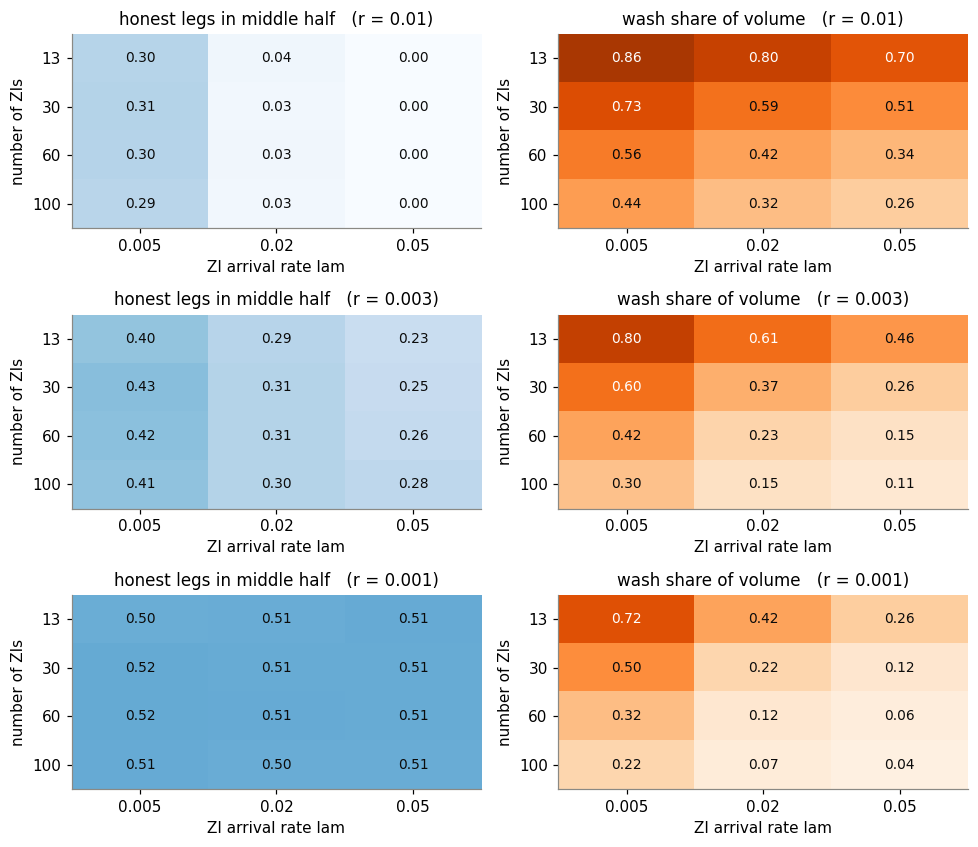

In [7]:
bg = load("bg_grid")
rs = sorted(bg["f_r"].unique(), reverse=True)
fig, axes = plt.subplots(len(rs), 2, figsize=(9, 2.6 * len(rs)), squeeze=False)
for i, r in enumerate(rs):
    for j, (scen, col, title, cmap) in enumerate([
            ("control", "background_middle_share", "honest legs in middle half", "Blues"),
            ("triad", "wash_leg_volume_share", "wash share of volume", "Oranges")]):
        sub = bg[(bg.f_r == r) & (bg.f_scenario == scen)]
        piv = sub.pivot_table(index="f_n_zi", columns="f_lam", values=col, aggfunc="mean")
        ax = axes[i][j]
        ax.imshow(piv.values, cmap=cmap, vmin=0, vmax=1, aspect="auto")
        ax.grid(False)
        ax.set_xticks(range(piv.shape[1]), [f"{c:g}" for c in piv.columns])
        ax.set_yticks(range(piv.shape[0]), piv.index)
        for (a, b), v in np.ndenumerate(piv.values):
            ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.6 else "#0b0b0b")
        ax.set_title(f"{title}   (r = {r:g})")
        ax.set_xlabel("ZI arrival rate lam")
        ax.set_ylabel("number of ZIs")
fig.tight_layout()

### Gap sweep: self-trade, interception and leakage (3 wallets)

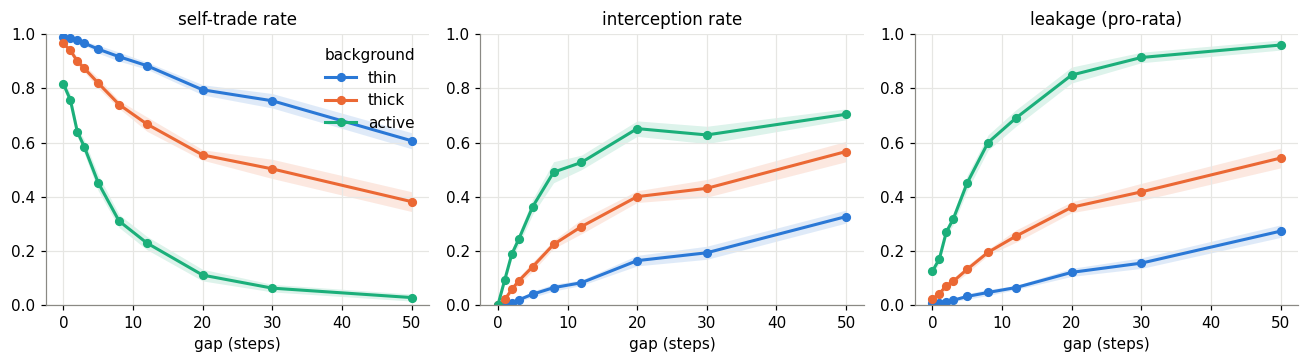

In [8]:
gp = load("gap")
gp = gp[gp.f_n_wallets == 3]
metrics = [("self_trade_rate", "self-trade rate"), ("intercept_rate", "interception rate"),
           ("leak_prorata", "leakage (pro-rata)")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharex=True)
for ax, (col, title) in zip(axes, metrics):
    for b in BG_ORDER:
        line_ci(ax, mean_ci(gp[gp.f_background == b], "f_gap", col), "f_gap", b, BG_COLOR[b])
    ax.set_title(title)
    ax.set_xlabel("gap (steps)")
    ax.set_ylim(0, 1)
axes[0].legend(title="background")
fig.tight_layout()

### Camouflage intensity: ordinary-trade share and leakage (triad)

Solid: all three wallets camouflage; dashed: one wallet. The leftmost point ("off") is the
same group without camouflage.

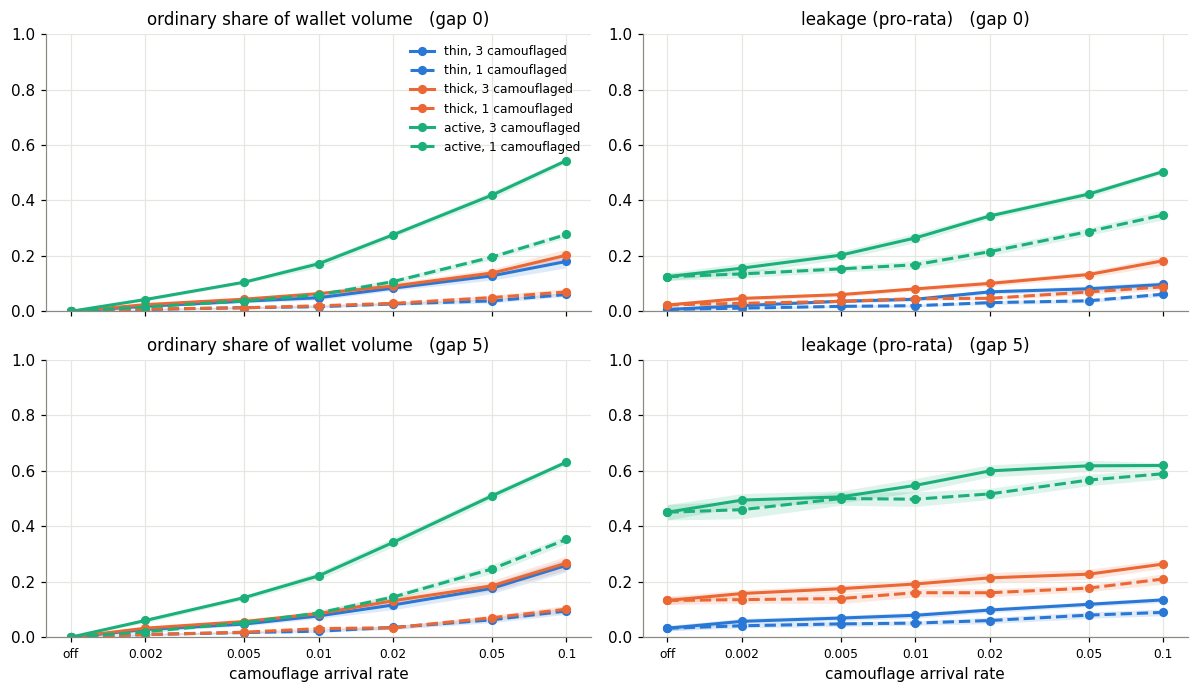

In [9]:
cm = load("camo")
rates = sorted(cm.loc[cm.f_camouflage_lam > 0, "f_camouflage_lam"].unique())
x0 = rates[0] / 2
gaps = sorted(cm.f_gap.unique())
fig, axes = plt.subplots(len(gaps), 2, figsize=(11, 3.2 * len(gaps)), sharex=True, squeeze=False)
for i, gap in enumerate(gaps):
    for j, (col, title) in enumerate([("wallet_ordinary_share", "ordinary share of wallet volume"),
                                      ("leak_prorata", "leakage (pro-rata)")]):
        ax = axes[i][j]
        for b in BG_ORDER:
            sub = cm[(cm.f_background == b) & (cm.f_gap == gap)]
            off = sub[sub.f_n_camouflage == 0]
            for n_c, ls in ((3, "-"), (1, "--")):
                d = pd.concat([off, sub[sub.f_n_camouflage == n_c]])
                d = d.assign(x=d.f_camouflage_lam.where(d.f_camouflage_lam > 0, x0))
                line_ci(ax, mean_ci(d, "x", col), "x", f"{b}, {n_c} camouflaged", BG_COLOR[b], ls)
        ax.set_xscale("log")
        ax.minorticks_off()
        ax.set_xticks([x0] + rates, ["off"] + [f"{r:g}" for r in rates], fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(f"{title}   (gap {gap})")
        if i == len(gaps) - 1:
            ax.set_xlabel("camouflage arrival rate")
axes[0][0].legend(fontsize=8)
fig.tight_layout()

### Wash intensity: wash share and leakage

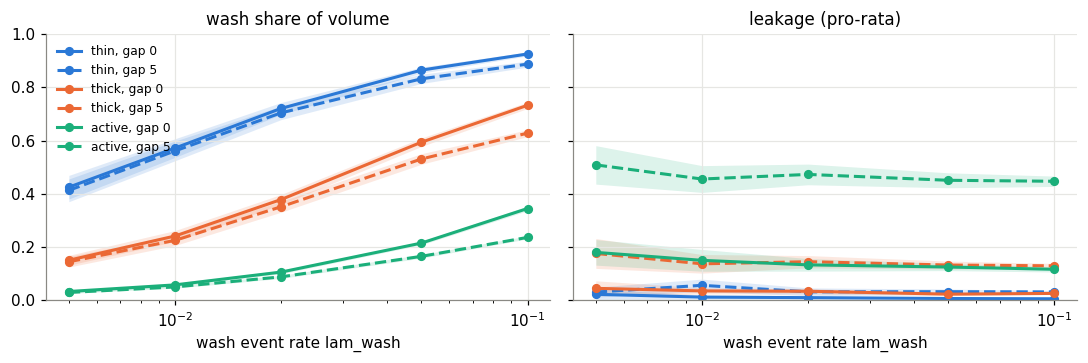

In [10]:
it = load("intensity")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (col, title) in zip(axes, [("wash_leg_volume_share", "wash share of volume"),
                                   ("leak_prorata", "leakage (pro-rata)")]):
    for b in BG_ORDER:
        for gap, ls in ((0, "-"), (5, "--")):
            sub = it[(it.f_background == b) & (it.f_gap == gap)]
            line_ci(ax, mean_ci(sub, "f_lam_wash", col), "f_lam_wash", f"{b}, gap {gap}",
                    BG_COLOR[b], ls)
    ax.set_xscale("log")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("wash event rate lam_wash")
axes[0].legend(fontsize=8)
fig.tight_layout()

### Price rule: midpoint vs microprice (seed means)

In [11]:
pr = load("price")
pr.groupby(["f_background", "f_gap", "f_price_rule"])[
    ["self_trade_rate", "intercept_rate", "leak_prorata", "wash_leg_volume_share"]
].mean().round(3).unstack("f_price_rule")

self_trade_rate        intercept_rate        leak_prorata  \
f_price_rule            microprice    mid     microprice    mid   microprice   
f_background f_gap                                                             
active       0               0.815  0.817          0.000  0.000        0.127   
             5               0.446  0.452          0.367  0.363        0.456   
             20              0.112  0.111          0.647  0.652        0.848   
thick        0               0.967  0.966          0.000  0.000        0.022   
             5               0.816  0.820          0.145  0.142        0.133   
             20              0.568  0.554          0.384  0.401        0.343   
thin         0               0.988  0.989          0.000  0.000        0.007   
             5               0.942  0.945          0.043  0.041        0.034   
             20              0.799  0.795          0.156  0.164        0.117   

                          wash_leg_volume_share         
f_price_rule          mid            microprice    mid  
f_background f_gap                                      
active       0      0.125                 0.215  0.215  
             5      0.451                 0.165  0.165  
             20     0.849                 0.103  0.103  
thick        0      0.023                 0.594  0.594  
             5      0.132                 0.529  0.531  
             20     0.361                 0.394  0.394  
thin         0      0.007                 0.865  0.865  
             5      0.032                 0.832  0.832  
             20     0.121                 0.744  0.742

### Named scenarios on every background (seed means)

In [12]:
sc = load("scenarios")
cols = ["self_trade_rate", "wash_leg_volume_share", "leak_prorata", "wallet_ordinary_share",
        "background_legs_per_agent"]
pd.set_option("display.max_rows", 200)
sc.groupby(["f_background", "f_scenario"])[cols].mean().round(3)

self_trade_rate  wash_leg_volume_share  \
f_background f_scenario                                               
active       control                     NaN                  0.000   
             dyad                      0.819                  0.214   
             hard                      0.352                  0.249   
             hard_hi                   0.273                  0.213   
             triad                     0.817                  0.215   
             triad_camo                0.794                  0.202   
             triad_camo_hi             0.796                  0.185   
             triad_camo_one            0.806                  0.204   
             triad_gap20               0.111                  0.103   
             triad_gap5                0.452                  0.165   
             triad_lowint              0.817                  0.058   
             triad_micro               0.446                  0.165   
             two_groups                0.816                  0.361   
active_dense control                     NaN                  0.000   
             dyad                      0.689                  0.116   
             hard                      0.191                  0.144   
             hard_hi                   0.168                  0.135   
             triad                     0.687                  0.117   
             triad_camo                0.644                  0.111   
             triad_camo_hi             0.661                  0.108   
             triad_camo_one            0.673                  0.114   
             triad_gap20               0.040                  0.054   
             triad_gap5                0.245                  0.085   
             triad_lowint              0.628                  0.029   
             triad_micro               0.246                  0.085   
             two_groups                0.669                  0.211   
active_thin  control                     NaN                  0.000   
             dyad                      0.971                  0.716   
             hard                      0.703                  0.725   
             hard_hi                   0.505                  0.470   
             triad                     0.971                  0.716   
             triad_camo                0.970                  0.661   
             triad_camo_hi             0.922                  0.494   
             triad_camo_one            0.960                  0.623   
             triad_gap20               0.692                  0.545   
             triad_gap5                0.877                  0.670   
             triad_lowint              0.959                  0.359   
             triad_micro               0.877                  0.670   
             two_groups                0.971                  0.840   
thick        control                     NaN                  0.000   
             dyad                      0.966                  0.594   
             hard                      0.627                  0.601   
             hard_hi                   0.583                  0.555   
             triad                     0.966                  0.594   
             triad_camo                0.965                  0.561   
             triad_camo_hi             0.957                  0.535   
             triad_camo_one            0.964                  0.577   
             triad_gap20               0.554                  0.394   
             triad_gap5                0.820                  0.531   
             triad_lowint              0.959                  0.242   
             triad_micro               0.816                  0.529   
             two_groups                0.964                  0.748   
thin         control                     NaN                  0.000   
             dyad                      0.989                  0.865   
             hard                      0.760         